# Global phage therapy research funding, 1999–2023: main analysis

This notebook rebuilds every figure and table of the preprint from one file,
`data/processed/phage_funding_analysis.csv` (802 grants, USD 318.6M), built by `01_preprocessing.ipynb`. Topics come from `02_topic_modelling.ipynb`.

**Corrections compared with the April 2025 notebooks**
- Growth is a log-linear trend on complete years 1999–2022, in USD. 2023 is shown but flagged as partial.
- Gender groups are exclusive: male only, female only, mixed, and no named researcher. Mixed teams are no longer counted twice.
- Grants shared by several institutions are split equally between those institutions (fractional counting), so totals add up to USD 318.6M.
- Grants whose text duplicated another grant now take that grant's topic. Only 1 grant remains unclassified, down from 18.
- Country labels come from one reference table (v1.1). Switzerland, Sweden and Spain are no longer counted as Global South, and EU funders are coded as "European Union".
- Every figure is drawn from the data. No numbers are typed into plotting code.
- Engagement types are reported under two definitions, as a sensitivity check.

The raw Dimensions export cannot be shared (Dimensions terms of use). See `data/README.md`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import phagefund as pf

DATA = ROOT / "data" / "processed" / "phage_funding_analysis.csv"
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": pf.FONT_SANS, "text.color": pf.INK, "axes.titlecolor": pf.INK,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": pf.INK2, "axes.labelcolor": pf.INK2, "xtick.color": pf.INK2, "ytick.color": pf.INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": pf.GRID, "grid.linewidth": 0.8, "figure.dpi": 110, "savefig.dpi": 300,
    "savefig.bbox": "tight", "legend.frameon": False,
})
def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG / f"{name}.{ext}")

d = pf.load(DATA)
print(f"{len(d)} grants, USD {d[pf.USD].sum()/1e6:.1f}M, {d[pf.YEAR].min()}–{d[pf.YEAR].max()}")

802 grants, USD 318.6M, 1999–2023


## Data quality (Supplementary Table S1)

In [2]:
cols = ["Grant ID", "Title", "Abstract", "Keywords", pf.USD, pf.YEAR, "End Year", "Researchers",
        pf.ORG, "Country of standardized research organization", pf.FUNDER, "Funder Country"]
s1 = pf.missingness(d, cols); s1.to_csv(TAB / "S1_missingness.csv"); s1

,Present,Missing,Missing (%)
Grant ID,802,0,0.0
Title,802,0,0.0
Abstract,712,90,11.2
Keywords,404,398,49.6
Funding amount in USD,802,0,0.0
Start Year,802,0,0.0
End Year,777,25,3.1
Researchers,743,59,7.4
Research Organization - standardized,802,0,0.0
Country of standardized research organization,802,0,0.0


## 1. Funding trends

Table 1 and Figure 1.

In [3]:
t1 = pf.by_period(d); t1.to_csv(TAB / "Table1_by_period.csv"); t1

,Grants,Total (USD M),Median (USD),Q1 (USD),Q3 (USD)
Period,,,,,
1999-2008,102.0,29.1,124007.0,28188.00,368145.00
2009-2015,198.0,76.6,140656.0,48250.00,410679.00
2016-2023,502.0,213.0,211446.0,40673.00,444375.00
All years,802.0,318.6,180000.0,40400.25,428116.25


In [4]:
y = pf.yearly(d)
growth = pd.DataFrame({
    "Grants": pf.loglinear_growth(y["grants"]),
    "Funding (USD)": pf.loglinear_growth(y["usd"]),
}).T
growth["Endpoint CAGR 1999-2022 (%)"] = [pf.endpoint_cagr(y["grants"], 1999, 2022), pf.endpoint_cagr(y["usd"], 1999, 2022)]
growth.to_csv(TAB / "S2_growth.csv"); growth

,annual_growth_pct,ci_low,ci_high,years,Endpoint CAGR 1999-2022 (%)
Grants,12.2,10.0,14.5,1999-2022,10.5
Funding (USD),16.6,12.6,20.7,1999-2022,16.3


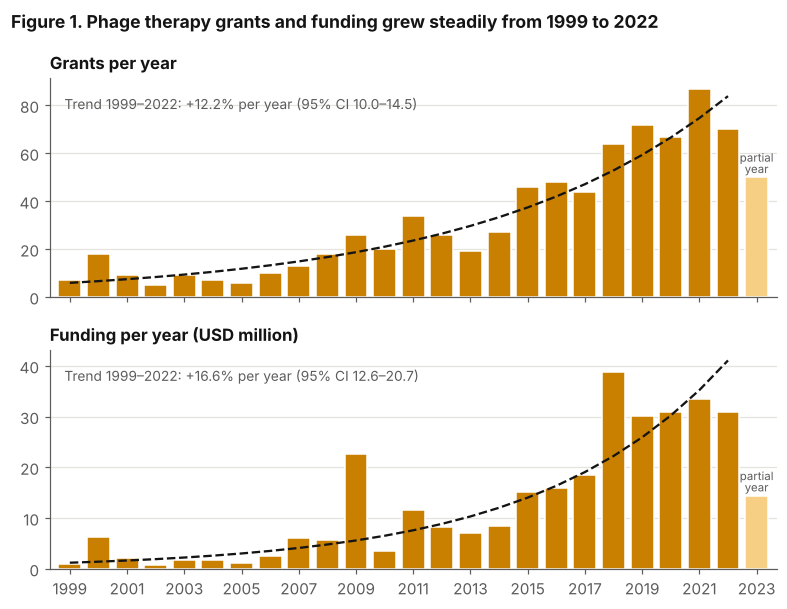

In [5]:
def trend_line(series, years=pf.TREND_YEARS):
    s = series.loc[years[0]:years[1]]
    b, a = np.polyfit(s.index - years[0], np.log(s.values), 1)
    return s.index, np.exp(a + b * (s.index - years[0]))

fig, axes = plt.subplots(2, 1, figsize=(7.2, 5.6), sharex=True)
panels = [("grants", "Grants per year", 1, "{:.0f}"), ("usd", "Funding per year (USD million)", 1e6, "{:.0f}")]
for ax, (col, title, scale, fmt) in zip(axes, panels):
    vals = y[col] / scale
    colors = [pf.PALETTE[0] if yr < pf.PARTIAL_YEAR else pf.PARTIAL for yr in y.index]
    ax.bar(y.index, vals, width=0.8, color=colors, edgecolor="white", linewidth=1)
    xs, fit = trend_line(y[col])
    g = pf.loglinear_growth(y[col])
    ax.plot(xs, fit / scale, color=pf.INK, lw=1.5, ls="--")
    ax.text(0.02, 0.92, f"Trend 1999–2022: +{g['annual_growth_pct']}% per year (95% CI {g['ci_low']}–{g['ci_high']})",
            transform=ax.transAxes, color=pf.INK2, fontsize=9, va="top")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
for ax, col, scale in [(axes[0], "grants", 1), (axes[1], "usd", 1e6)]:
    ax.text(2023, y.loc[2023, col] / scale, "partial\nyear", ha="center", va="bottom", fontsize=7.5, color=pf.INK2, linespacing=0.9)
axes[1].set_xticks(range(1999, 2024, 2)); axes[1].set_xlim(1998.3, 2023.7)
fig.suptitle("Figure 1. Phage therapy grants and funding grew steadily from 1999 to 2022", x=0.01, ha="left",
             fontsize=11.5, fontweight="bold")
fig.tight_layout(); save(fig, "Fig1_trends"); plt.show()

## 2. Research topics

The topic for each grant comes from the 2024 LDA run (k = 5, seed 111). See `02_topic_modelling.ipynb` for the method, the coherence curve and the stability check.

In [6]:
order = ["Infectious disease control", "Bacterial genetics and mechanisms", "Antibiotic resistance strategies",
         "Immunotherapy and targeted treatments", "Unclassified"]
tt = d.groupby("topic").agg(Grants=("Grant ID", "count"), usd=(pf.USD, "sum"), median=(pf.USD, "median")).reindex(order)
tt["Total (USD M)"] = (tt.pop("usd") / 1e6).round(1); tt["Median (USD)"] = tt.pop("median").round(0)
tt["Share of funding (%)"] = (tt["Total (USD M)"] / (d[pf.USD].sum() / 1e6) * 100).round(1)
tt.to_csv(TAB / "Table3_topics.csv"); tt

,Grants,Total (USD M),Median (USD),Share of funding (%)
topic,,,,
Infectious disease control,280,114.5,194706.0,35.9
Bacterial genetics and mechanisms,237,91.7,171755.0,28.8
Antibiotic resistance strategies,151,71.4,242263.0,22.4
Immunotherapy and targeted treatments,133,41.0,111442.0,12.9
Unclassified,1,0.0,49400.0,0.0


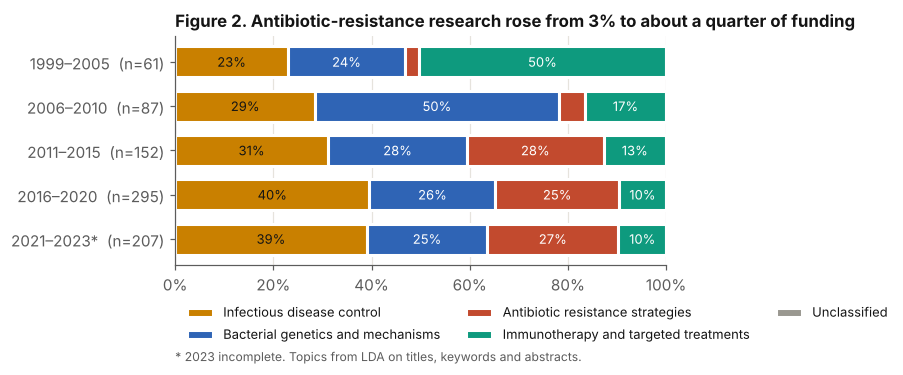

In [7]:
period = pd.cut(d[pf.YEAR], [1998, 2005, 2010, 2015, 2020, 2023],
                labels=["1999–2005", "2006–2010", "2011–2015", "2016–2020", "2021–2023*"])
share = (d.groupby([period, "topic"], observed=True)[pf.USD].sum().unstack().reindex(columns=order).fillna(0))
share = share.div(share.sum(axis=1), axis=0) * 100
counts = d.groupby(period, observed=True).size()

fig, ax = plt.subplots(figsize=(7.2, 3.9))
left = np.zeros(len(share))
colors = pf.PALETTE[:4] + [pf.NEUTRAL]
for t, c in zip(order, colors):
    ax.barh(range(len(share)), share[t], left=left, color=c, edgecolor="white", linewidth=2, height=0.7, label=t)
    for i, v in enumerate(share[t]):
        if v >= 9:
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color=pf.INK if c == pf.PALETTE[0] else "white")
    left += share[t].values
ax.set_yticks(range(len(share)), [f"{p}  (n={n})" for p, n in zip(share.index, counts)])
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.12), fontsize=8.5)
ax.set_title("Figure 2. Antibiotic-resistance research rose from 3% to about a quarter of funding")
ax.text(0, -0.42, "* 2023 incomplete. Topics from LDA on titles, keywords and abstracts.",
        transform=ax.transAxes, fontsize=8, color=pf.INK2)
fig.tight_layout(); save(fig, "Fig2_topics"); plt.show()

## 3. Gender

In [8]:
t4 = pf.gender_table(d); t4.to_csv(TAB / "Table4_gender.csv"); t4

,Grants,Total (USD M),Share of funding (%),Mean (USD),Median (USD),Median team size
Team composition,,,,,,
Male only,446,179.0,56.2,401439.0,164100.0,1.0
Female only,201,57.4,18.0,285350.0,129265.0,1.0
Mixed,95,41.6,13.1,437716.0,237406.0,5.0
No named researcher,60,40.7,12.8,677532.0,295922.0,0.0


In [9]:
tests = pf.gender_tests(d); tests.to_csv(TAB / "S3_gender_tests.csv")
print("n =", tests.attrs["n"], "| controls:", tests.attrs["controls"]); tests

n = 742 | controls: log team size, US funder, start year; robust (HC1) errors


,Mann-Whitney p,Adjusted difference (%),95% CI low (%),95% CI high (%),Regression p
Comparison,,,,,
Female only vs Male only,0.047,-27.275,-42.739,-7.635,0.009
Mixed vs Male only,0.045,58.401,7.860,132.625,0.019


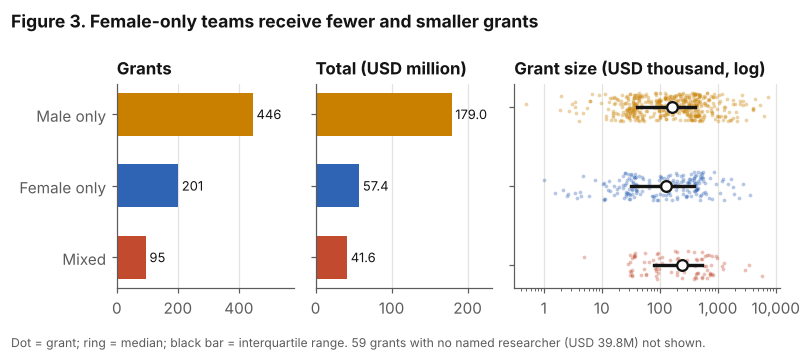

In [10]:
groups = ["Male only", "Female only", "Mixed"]
gcol = dict(zip(groups, pf.PALETTE[:3]))
fig, axes = plt.subplots(1, 3, figsize=(7.4, 3.0), gridspec_kw={"width_ratios": [1, 1, 1.5]})
for ax, col, title, fmt in [(axes[0], "Grants", "Grants", "{:.0f}"),
                            (axes[1], "Total (USD M)", "Total (USD million)", "{:.1f}")]:
    v = t4.loc[groups, col]
    ax.barh(groups, v, color=[gcol[g] for g in groups], height=0.6)
    for i, x in enumerate(v):
        ax.text(x, i, " " + fmt.format(x), va="center", fontsize=8.5, color=pf.INK)
    ax.set_title(title); ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlim(0, v.max() * 1.3)
axes[1].set_yticklabels([])
ax = axes[2]
for i, g in enumerate(groups):
    v = d.loc[d.team_gender == g, pf.USD] / 1e3
    q1, med, q3 = v.quantile([.25, .5, .75])
    jitter = np.random.default_rng(1).uniform(-0.18, 0.18, len(v))
    ax.scatter(v, i + jitter, s=6, color=gcol[g], alpha=0.35, linewidths=0)
    ax.plot([q1, q3], [i, i], color=pf.INK, lw=2.2)
    ax.plot(med, i, "o", color="white", mec=pf.INK, mew=1.5, ms=7)
ax.set_xscale("log"); ax.set_yticks(range(3), []); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_title("Grant size (USD thousand, log)")
fig.suptitle("Figure 3. Female-only teams receive fewer and smaller grants", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.text(0.01, -0.04, "Dot = grant; ring = median; black bar = interquartile range. 59 grants with no named researcher (USD 39.8M) not shown.",
         fontsize=8, color=pf.INK2)
fig.tight_layout(); save(fig, "Fig3_gender"); plt.show()

## 4. Geography and income

Each grant has one funder. A grant with *k* recipient institutions gives 1/*k* of its amount to each institution, and through it to that institution's country and income group.

In [11]:
income_order = ["High income", "Upper middle income", "Lower middle income", "Low income"]
fund_inc = d.groupby("Funder Income group")[pf.USD].sum().reindex(income_order).fillna(0) / d[pf.USD].sum() * 100
rec_inc = pf.fractional_aligned(d, "receiver_income_list")["share_usd"].reindex(income_order).fillna(0) * 100
ns = pd.DataFrame({
    "Funders (%)": d.groupby("funder Global north - south")[pf.USD].sum() / d[pf.USD].sum() * 100,
    "Recipients, fractional (%)": pf.fractional_aligned(d, "receiver_north_south_list")["share_usd"] * 100,
}).round(1)
t5 = pd.DataFrame({"Funders (%)": fund_inc, "Recipients, fractional (%)": rec_inc}).round(2)
t5.to_csv(TAB / "Table5_income_groups.csv"); ns.to_csv(TAB / "S4_north_south.csv")
display(t5); ns

,Funders (%),"Recipients, fractional (%)"
High income,98.25,97.78
Upper middle income,1.57,1.89
Lower middle income,0.18,0.29
Low income,0.00,0.05


,Funders (%),"Recipients, fractional (%)"
Global North,98.3,97.9
Global South,1.7,2.1


In [12]:
fund_ctry = (d.groupby("Funder Country")[pf.USD].sum() / 1e6).sort_values(ascending=False)
rec_ctry = (pf.fractional_aligned(d, "receiver_country_list")["usd_frac"] / 1e6)
ctry = pd.DataFrame({"Funder (USD M)": fund_ctry, "Recipient, fractional (USD M)": rec_ctry}).fillna(0).round(2)
ctry = ctry.sort_values("Recipient, fractional (USD M)", ascending=False)
ctry.to_csv(TAB / "S5_countries.csv"); ctry.head(15)

,Funder (USD M),"Recipient, fractional (USD M)"
United States,151.84,151.31
United Kingdom,25.62,22.95
Czechia,18.58,18.58
Japan,13.46,13.46
Germany,10.65,12.97
Switzerland,12.27,12.62
Poland,12.54,12.54
Australia,11.01,12.06
France,6.29,11.98
Canada,11.13,11.68


### Who are the Global South recipients? (Table S11)
"Global South" mixes very different countries, so it is broken down here by country.

In [13]:
rows = []
for c, nsl, amt in zip(d["receiver_country_list"], d["receiver_north_south_list"], d[pf.USD]):
    cs, nss = str(c).split(";"), str(nsl).split(";")
    for cc, nn in zip(cs, nss):
        rows.append((cc, nn, amt / len(cs)))
gsc = pd.DataFrame(rows, columns=["country", "north_south", "usd"])
s11 = (gsc[gsc.north_south == "Global South"].groupby("country")["usd"].agg(["count", "sum"])
       .rename(columns={"count": "Recipient entries", "sum": "USD"}).sort_values("USD", ascending=False))
s11["USD (M)"] = (s11.pop("USD") / 1e6).round(2)
s11["Share of all funding (%)"] = (s11["USD (M)"] / (d[pf.USD].sum() / 1e6) * 100).round(2)
s11.loc["Total Global South"] = [s11["Recipient entries"].sum(), s11["USD (M)"].sum(), s11["Share of all funding (%)"].sum()]
s11.to_csv(TAB / "S11_global_south_recipients.csv"); s11

,Recipient entries,USD (M),Share of all funding (%)
country,,,
China,84.0,4.91,1.54
India,13.0,0.81,0.25
Thailand,3.0,0.31,0.10
South Africa,2.0,0.17,0.05
Brazil,1.0,0.15,0.05
Uganda,2.0,0.15,0.05
Singapore,2.0,0.14,0.04
Tanzania,1.0,0.07,0.02
Total Global South,108.0,6.71,2.10


### Domestic vs cross-border funding (Table S12)
A grant counts as domestic when every recipient institution is in the funder's country.

In [14]:
d["domestic"] = [all(x == fc for x in str(rc).split(";") if x) for fc, rc in zip(d["Funder Country"], d["receiver_country_list"])]
s12 = pd.DataFrame({
    "Grants": d.groupby("domestic").size(),
    "USD (M)": (d.groupby("domestic")[pf.USD].sum() / 1e6).round(1),
}).rename(index={True: "Domestic", False: "Cross-border"})
s12["Share of funding (%)"] = (s12["USD (M)"] / s12["USD (M)"].sum() * 100).round(1)
s12.to_csv(TAB / "S12_domestic_vs_crossborder.csv")
display(s12)
cb = (d[~d.domestic].groupby("Funder")[pf.USD].agg(["count", "sum"]).sort_values("sum", ascending=False).head(8))
cb["sum"] = (cb["sum"] / 1e6).round(2); cb.columns = ["Cross-border grants", "USD (M)"]
cb.to_csv(TAB / "S13_crossborder_funders.csv"); cb

,Grants,USD (M),Share of funding (%)
domestic,,,
Cross-border,65,36.1,11.3
Domestic,737,282.5,88.7


,Cross-border grants,USD (M)
Funder,,
European Commission,19,14.64
Biotechnology and Biological Sciences Research Council,12,5.60
Swiss National Science Foundation,8,5.12
European Research Council,4,4.18
Engineering and Physical Sciences Research Council,1,2.02
National Institute of Allergy and Infectious Diseases,5,1.91
Australian Research Council,2,0.83
Medical Research Council,1,0.61


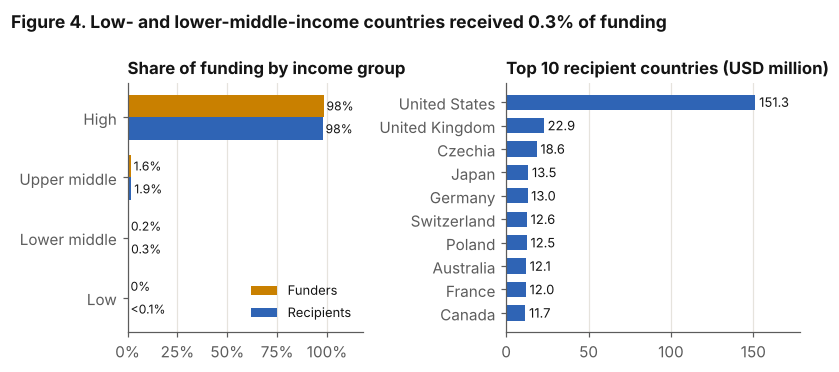

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.4), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
labels = ["High", "Upper middle", "Lower middle", "Low"]
yy = np.arange(4); h = 0.38
fmt = lambda v: "<0.1%" if 0 < v < 0.1 else ("0%" if v == 0 else (f"{v:.1f}%" if v < 10 else f"{v:.0f}%"))
for off, col, c, lab in [(-h/2, "Funders (%)", pf.PALETTE[0], "Funders"), (h/2, "Recipients, fractional (%)", pf.PALETTE[1], "Recipients")]:
    v = t5[col].values
    ax.barh(yy + off, v, h, color=c, label=lab)
    for yi, vi in zip(yy + off, v):
        ax.text(vi + 1.5, yi, fmt(vi), va="center", fontsize=8, color=pf.INK)
ax.set_yticks(yy, labels); ax.invert_yaxis(); ax.set_xlim(0, 118)
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.grid(axis="y", visible=False)
ax.set_title("Share of funding by income group"); ax.legend(loc="lower right", fontsize=8.5)
ax = axes[1]
top = ctry.head(10)["Recipient, fractional (USD M)"][::-1]
ax.barh(top.index, top.values, color=pf.PALETTE[1], height=0.65)
for i, v in enumerate(top.values):
    ax.text(v, i, f" {v:.1f}", va="center", fontsize=8.5, color=pf.INK)
ax.set_title("Top 10 recipient countries (USD million)"); ax.grid(axis="y", visible=False); ax.set_xlim(0, top.max() * 1.18)
fig.suptitle("Figure 4. Low- and lower-middle-income countries received 0.3% of funding", x=0.01, ha="left",
             fontsize=11.5, fontweight="bold")
fig.tight_layout(); save(fig, "Fig4_geography"); plt.show()

## 5. Funders and recipients (Table 2)

In [16]:
t2a = pf.top_funders(d); t2a.to_csv(TAB / "Table2a_top_funders.csv"); t2a

,Country,Grants,Total (USD M),Share (%)
Funder,,,,
National Institute of Allergy and Infectious Diseases,United States,81,66.9,21.0
National Cancer Institute,United States,12,15.5,4.9
European Commission,European Union,19,14.6,4.6
Swiss National Science Foundation,Switzerland,26,11.8,3.7
Biotechnology and Biological Sciences Research Council,United Kingdom,24,11.2,3.5
Federal Ministry of Education and Research,Germany,10,10.1,3.2
Congressionally Directed Medical Research Programs,United States,21,9.2,2.9
National Institute of General Medical Sciences,United States,11,9.1,2.9
Ministry of Industry and Trade,Czechia,5,8.5,2.7


In [17]:
t2b = pf.top_recipients(d); t2b.to_csv(TAB / "Table2b_top_recipients.csv"); t2b

,Grants,"Total (USD M, fractional)"
receiver_org_list,,
Intralytix (United States),9,8.46
Division Of Basic Sciences - Nci,1,7.22
Purdue University West Lafayette,3,6.90
Dyntec (Czechia),2,6.75
University Of Montana,2,5.76
Fraunhofer Society,1,5.24
University Of Toronto,9,5.17
Stanford University,7,4.83
Mb Pharma (Czechia),2,4.71


In [18]:
by_count = d.groupby(pf.FUNDER).size().sort_values(ascending=False).head(10).rename("Grants")
by_count.to_csv(TAB / "S6_funders_by_count.csv"); by_count

Funder
Japan Society for the Promotion of Science                105
National Institute of Allergy and Infectious Diseases      81
National Natural Science Foundation of China               79
Natural Sciences and Engineering Research Council          43
Fundação para a Ciência e Tecnologia                       31
National Science Center                                    27
Swiss National Science Foundation                          26
National Institute of Food and Agriculture                 24
Biotechnology and Biological Sciences Research Council     24
Congressionally Directed Medical Research Programs         21
Name: Grants, dtype: int64

## 6. Researcher engagement (sensitivity check)

Rules are the same as in the patent study. A label is given in each year an entity is active, and the summary uses its last label:
Newcomer = not active before, active later (or first seen in 2023); Continuant = active before and after;
Terminator = active before, not after; Transient = active in one year only.

In [19]:
eng = pf.engagement_summary(d); eng.to_csv(TAB / "S7_engagement_definitions.csv")
print(f"{eng.attrs['n_researchers']} researchers; {eng.attrs['single_grant_share']}% held a single grant")
eng

1073 researchers; 83.9% held a single grant


,Start year only (n),Full grant span (n),Start year only (%),Full grant span (%)
label,,,,
Continuant,14,291,1.3,27.1
Newcomer,45,45,4.2,4.2
Terminator,133,699,12.4,65.1
Transient,881,38,82.1,3.5


In [20]:
# Numbers quoted in the text
summary = {
    "grants": len(d), "usd_m": round(d[pf.USD].sum() / 1e6, 1),
    "median_grant": d[pf.USD].median(), "niaid_share_pct": round(t2a.iloc[0]["Share (%)"], 1),
    "global_north_funders_pct": float(ns.loc["Global North", "Funders (%)"]),
    "lmic_low_recipients_pct": round(float(t5.loc[["Lower middle income", "Low income"], "Recipients, fractional (%)"].sum()), 2),
    "high_income_recipients_pct": round(float(t5.loc["High income", "Recipients, fractional (%)"]), 1),
    "global_south_recipients_pct": float(ns.loc["Global South", "Recipients, fractional (%)"]),
    "china_share_of_global_south_pct": round(float(s11.loc["China", "USD (M)"] / s11.loc["Total Global South", "USD (M)"] * 100), 1),
    "domestic_funding_pct": float(s12.loc["Domestic", "Share of funding (%)"]),
    "grant_growth": pf.loglinear_growth(y["grants"]), "usd_growth": pf.loglinear_growth(y["usd"]),
}
pd.Series(summary).to_json(TAB / "key_numbers.json", indent=2); summary

{'grants': 802,
 'usd_m': np.float64(318.6),
 'median_grant': np.float64(180000.0),
 'niaid_share_pct': np.float64(21.0),
 'global_north_funders_pct': 98.3,
 'lmic_low_recipients_pct': 0.34,
 'high_income_recipients_pct': 97.8,
 'global_south_recipients_pct': 2.1,
 'china_share_of_global_south_pct': 73.2,
 'domestic_funding_pct': 88.7,
 'grant_growth': {'annual_growth_pct': np.float64(12.2),
  'ci_low': np.float64(10.0),
  'ci_high': np.float64(14.5),
  'years': '1999-2022'},
 'usd_growth': {'annual_growth_pct': np.float64(16.6),
  'ci_low': np.float64(12.6),
  'ci_high': np.float64(20.7),
  'years': '1999-2022'}}